In [ ]:
import random
import numpy as np
import torch

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)

In [ ]:
# =====================================================================
# SYSTEM INITIALIZER & MULTI-MODAL DEPENDENCY INSTALLATION
# =====================================================================
import sys
import os

print("⏳ Initializing environment and installing multi-modal architecture toolkit...")

# Install core boosting, optimization, and transformer frameworks
!pip install catboost xgboost optuna transformers datasets accelerate -q

print("\n=====================================================================")
print("🎉 SYSTEM INITIALIZATION COMPLETE: All engines ready for execution.")
print("=====================================================================")

⏳ Initializing environment and installing multi-modal architecture toolkit...

🎉 SYSTEM INITIALIZATION COMPLETE: All engines ready for execution.


In [ ]:
# Install RDKit
!pip install rdkit -q

import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from rdkit import Chem
from rdkit.Chem import Draw
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import files
import io

print("Please select your train.csv and test.csv files:")
uploaded = files.upload()

# This forces Colab to open a direct browser file-picker window.

Please select your train.csv and test.csv files:


Saving test.csv to test.csv
Saving train.csv to train.csv


In [ ]:
# Read the datasets from Colab local workspace root
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

print(f"Train Shape: {train_df.shape} | Test Shape: {test_df.shape}")
print("Columns available:", train_df.columns.tolist())

# Adjust column names below if your columns are labeled differently (e.g., 'LogS')
SMILES_COL = 'SMILES'
TARGET_COL = 'Solubility'

# Preview target range
print(f"Training target range: {train_df[TARGET_COL].min()} to {train_df[TARGET_COL].max()}")

Train Shape: (7984, 7) | Test Shape: (1996, 7)
Columns available: ['ID', 'Name', 'InChIKey', 'SMILES', 'Solubility', 'canonical_smiles', 'scaffold']
Training target range: -13.1719 to 2.1376816201


#CNN

In [ ]:
def smiles_to_cnn_input(smiles_series, targets, img_size=(128, 128)):
    X_images = []
    y_targets = []

    for idx, (smiles, target) in enumerate(zip(smiles_series, targets)):
        mol = Chem.MolFromSmiles(smiles)
        if mol is not None:
            # Render clean, standardized 2D drawing
            img = Draw.MolToImage(mol, size=img_size, fitImage=True)
            # Convert PIL image to grayscale ('L')
            img_gray = img.convert('L')
            # Convert to numpy array and normalize pixel intensities
            img_array = np.array(img_gray) / 255.0

            X_images.append(img_array)
            y_targets.append(target)

    # Reshape arrays to append the channel dimension required by Keras Conv2D (Height, Width, Channels)
    X_data = np.array(X_images).reshape(-1, img_size[0], img_size[1], 1)
    y_data = np.array(y_targets, dtype=np.float32)

    return X_data, y_data

print("Converting training molecules to images...")
X_train, y_train = smiles_to_cnn_input(train_df[SMILES_COL], train_df[TARGET_COL])

print("Converting test molecules to images...")
X_test, y_test = smiles_to_cnn_input(test_df[SMILES_COL], test_df[TARGET_COL])

print(f"Final Tensor Dimensions -> X_train: {X_train.shape}, y_train: {y_train.shape}")

Converting training molecules to images...


[08:50:32] unsupported number of radical electrons 4
[08:50:33] WARNING: not removing hydrogen atom without neighbors
[08:50:33] WARNING: not removing hydrogen atom without neighbors
[08:50:33] WARNING: not removing hydrogen atom without neighbors
[08:50:33] unsupported number of radical electrons 4
[08:50:34] WARNING: not removing hydrogen atom without neighbors
[08:50:34] WARNING: not removing hydrogen atom without neighbors
[08:50:34] WARNING: not removing hydrogen atom without neighbors
[08:50:34] unsupported number of radical electrons 4
[08:50:35] WARNING: not removing hydrogen atom without neighbors
[08:50:35] WARNING: not removing hydrogen atom without neighbors
[08:50:35] WARNING: not removing hydrogen atom without neighbors
[08:50:37] WARNING: not removing hydrogen atom without neighbors
[08:50:37] WARNING: not removing hydrogen atom without neighbors
[08:50:37] WARNING: not removing hydrogen atom without neighbors
[08:50:37] WARNING: not removing hydrogen atom without neighb

Converting test molecules to images...


[08:50:57] WARNING: not removing hydrogen atom without neighbors
[08:50:57] WARNING: not removing hydrogen atom without neighbors
[08:50:57] WARNING: not removing hydrogen atom without neighbors
[08:50:57] WARNING: not removing hydrogen atom without neighbors
[08:50:57] WARNING: not removing hydrogen atom without neighbors
[08:50:57] WARNING: not removing hydrogen atom without neighbors
[08:50:58] WARNING: not removing hydrogen atom without neighbors


Final Tensor Dimensions -> X_train: (7984, 128, 128, 1), y_train: (7984,)


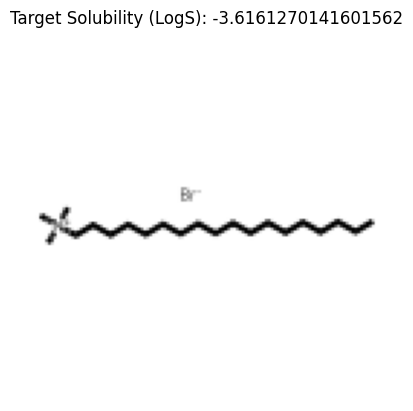

In [ ]:
plt.imshow(X_train[0].squeeze(), cmap='gray')
plt.title(f"Target Solubility (LogS): {y_train[0]}")
plt.axis('off')
plt.show()

In [ ]:
def build_molecular_cnn(input_shape=(128, 128, 1)):
    model = models.Sequential([
        # First Convolutional Block
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),

        # Second Convolutional Block
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Third Convolutional Block
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Flattening structural maps into dense representation vectors
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.2),  # Prevents overfitting on small 10k structural features

        # Linear output layer for continuous scalar prediction
        layers.Dense(1, activation='linear')
    ])

    # Using Mean Squared Error (MSE) loss for regression optimization
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae', tf.keras.metrics.RootMeanSquaredError(name='rmse')]
    )
    return model

model = build_molecular_cnn()
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,193 (12.60 MB)

 Trainable params: 3,304,193 (12.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Stop training if validation loss doesn't improve for 5 consecutive epochs
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=40,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 21s 72ms/step - loss: 5.5446 - mae: 1.8462 - rmse: 2.3547 - val_loss: 2.8693 - val_mae: 1.3680 - val_rmse: 1.6939
Epoch 2/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 4.0649 - mae: 1.5752 - rmse: 2.0162 - val_loss: 2.4131 - val_mae: 1.2119 - val_rmse: 1.5534
Epoch 3/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - loss: 3.7401 - mae: 1.5060 - rmse: 1.9339 - val_loss: 2.3447 - val_mae: 1.1789 - val_rmse: 1.5312
Epoch 4/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 3.4316 - mae: 1.4429 - rmse: 1.8525 - val_loss: 2.2774 - val_mae: 1.1836 - val_rmse: 1.5091
Epoch 5/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 3.0215 - mae: 1.3454 - rmse: 1.7382 - val_loss: 2.2181 - val_mae: 1.1674 - val_rmse: 1.4893
Epoch 6/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - loss: 2.7912 - mae: 1.2921 - rmse: 1.6707 - val_loss: 2.2505 - val_mae: 1.1797 - val_rmse: 1.5002
Epoch 7/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 2.4101 - mae: 1.2082

In [ ]:
test_loss, test_mae, test_rmse = model.evaluate(X_test, y_test, verbose=0)
print(f"=== Test Evaluation Metrics ===")
print(f"Mean Absolute Error (MAE): {test_mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {test_rmse:.4f}")

# Calculate R2 Score manually or using sklearn
from sklearn.metrics import r2_score
predictions = model.predict(X_test).flatten()
r2 = r2_score(y_test, predictions)
print(f"R2 Score: {r2:.4f}")

=== Test Evaluation Metrics ===
Mean Absolute Error (MAE): 1.5217
Root Mean Squared Error (RMSE): 1.9614
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
R2 Score: 0.2734


#GNN

In [ ]:
!pip install torch-geometric -q

import torch
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from rdkit import Chem
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("PyTorch Geometric installed successfully!")
print("Using GPU:", torch.cuda.is_available())

PyTorch Geometric installed successfully!
Using GPU: True


In [ ]:
def smiles_to_advanced_graph(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = []
    for atom in mol.GetAtoms():
        # 1. Atom Identity (One-hot encoded) - 8 dims
        num = atom.GetAtomicNum()
        identity = [1 if num == a else 0 for a in [6, 7, 8, 9, 16, 17, 35, 53]]

        # 2. Hybridization type (One-hot encoded) - 3 dims (SP, SP2, SP3)
        hyb = atom.GetHybridization()
        hybridization = [
            1 if hyb == Chem.HybridizationType.SP else 0,
            1 if hyb == Chem.HybridizationType.SP2 else 0,
            1 if hyb == Chem.HybridizationType.SP3 else 0
        ]

        # 3. Explicit Structural & Thermodynamic Properties - 6 dims
        aromatic = [1 if atom.GetIsAromatic() else 0] # 1 dim
        num_h = [atom.GetTotalNumHs()] # 1 dim (Crucial for H-bonding solvation)
        formal_charge = [atom.GetFormalCharge()] # 1 dim
        chiral = [1 if atom.HasProp('_ChiralityPossible') else 0] # 1 dim
        valence = [atom.GetTotalValence()] # 1 dim
        degree = [atom.GetDegree()] # 1 dim

        # Combine everything into a unified 17-dimensional feature vector per atom
        feat = identity + hybridization + aromatic + num_h + formal_charge + chiral + valence + degree
        atom_features.append(feat)

    x = torch.tensor(atom_features, dtype=torch.float)

    # Extract Bond Connectivity (Undirected edge index)
    edge_indices = []
    for bond in mol.GetBonds():
        start = bond.GetBeginAtomIdx()
        end = bond.GetEndAtomIdx()
        edge_indices.append([start, end])
        edge_indices.append([end, start])

    if len(edge_indices) == 0:
        edge_index = torch.empty((2, 0), dtype=torch.long)
    else:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

    y = torch.tensor([target], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

print("Converting SMILES to advanced 17-feature graphs...")
train_graphs = [smiles_to_advanced_graph(s, t) for s, t in zip(train_df[SMILES_COL], train_df[TARGET_COL])]
train_graphs = [g for g in train_graphs if g is not None]

test_graphs = [smiles_to_advanced_graph(s, t) for s, t in zip(test_df[SMILES_COL], test_df[TARGET_COL])]
test_graphs = [g for g in test_graphs if g is not None]

train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)
print("Advanced DataLoaders ready without errors!")

Converting SMILES to advanced 17-feature graphs...


[08:52:23] WARNING: not removing hydrogen atom without neighbors
[08:52:23] WARNING: not removing hydrogen atom without neighbors
[08:52:23] WARNING: not removing hydrogen atom without neighbors
[08:52:23] WARNING: not removing hydrogen atom without neighbors
[08:52:23] WARNING: not removing hydrogen atom without neighbors
[08:52:23] WARNING: not removing hydrogen atom without neighbors
[08:52:23] WARNING: not removing hydrogen atom without neighbors
[08:52:23] WARNING: not removing hydrogen atom without neighbors
[08:52:24] WARNING: not removing hydrogen atom without neighbors
[08:52:24] WARNING: not removing hydrogen atom without neighbors
[08:52:24] WARNING: not removing hydrogen atom without neighbors
[08:52:24] WARNING: not removing hydrogen atom without neighbors
[08:52:24] WARNING: not removing hydrogen atom without neighbors
[08:52:24] WARNING: not removing hydrogen atom without neighbors
[08:52:24] WARNING: not removing hydrogen atom without neighbors
[08:52:24] WARNING: not r

Advanced DataLoaders ready without errors!


/tmp/ipykernel_3130/3176540707.py:57: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
/tmp/ipykernel_3130/3176540707.py:58: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)


In [ ]:
class MolecularGCN(torch.nn.Module):
    def __init__(self, num_node_features):
        super(MolecularGCN, self).__init__()
        # 3 Graph Convolutional Layers
        self.conv1 = GCNConv(num_node_features, 64)
        self.conv2 = GCNConv(64, 128)
        self.conv3 = GCNConv(128, 64)

        # Regression Fully Connected Head
        self.fc1 = torch.nn.Linear(64, 32)
        self.fc2 = torch.nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch

        # 1. Message Passing / Node updates
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = self.conv3(x, edge_index)
        x = F.relu(x)

        # 2. Pooling layer: Aggregate atom states into a single molecule state vector
        x = global_mean_pool(x, batch)

        # 3. Predict Solubility Value
        x = F.relu(self.fc1(x))
        x = F.dropout(x, p=0.2, training=self.training)
        return self.fc2(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MolecularGCN(num_node_features=17).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = torch.nn.MSELoss()

In [ ]:
model.train()
for epoch in range(30):
    total_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        out = model(batch)
        loss = criterion(out.squeeze(), batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:02d} | Train MSE Loss: {total_loss / len(train_loader.dataset):.4f}")

Epoch 01 | Train MSE Loss: 6.3104
Epoch 05 | Train MSE Loss: 2.9127
Epoch 10 | Train MSE Loss: 2.5769
Epoch 15 | Train MSE Loss: 2.4450
Epoch 20 | Train MSE Loss: 2.2504
Epoch 25 | Train MSE Loss: 2.1571
Epoch 30 | Train MSE Loss: 2.0604


In [ ]:
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        out = model(batch)
        all_preds.extend(out.squeeze().cpu().numpy())
        all_targets.extend(batch.y.cpu().numpy())

# Statistics
gnn_mae = mean_absolute_error(all_targets, all_preds)
gnn_rmse = np.sqrt(mean_squared_error(all_targets, all_preds))
gnn_r2 = r2_score(all_targets, all_preds)

print("=== True PyTorch GNN Evaluation Metrics ===")
print(f"Mean Absolute Error (MAE): {gnn_mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {gnn_rmse:.4f}")
print(f"R2 Score: {gnn_r2:.4f}")

=== True PyTorch GNN Evaluation Metrics ===
Mean Absolute Error (MAE): 1.1825
Root Mean Squared Error (RMSE): 1.4843
R2 Score: 0.5839


#GAT

In [ ]:
from torch_geometric.nn import GATv2Conv
import torch.nn as nn

def smiles_to_complete_graph(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    # 1. Node Features (Same 17-dimensional vector)
    atom_features = []
    for atom in mol.GetAtoms():
        num = atom.GetAtomicNum()
        identity = [1 if num == a else 0 for a in [6, 7, 8, 9, 16, 17, 35, 53]]
        hyb = atom.GetHybridization()
        hybridization = [
            1 if hyb == Chem.HybridizationType.SP else 0,
            1 if hyb == Chem.HybridizationType.SP2 else 0,
            1 if hyb == Chem.HybridizationType.SP3 else 0
        ]
        aromatic = [1 if atom.GetIsAromatic() else 0]
        num_h = [atom.GetTotalNumHs()]
        formal_charge = [atom.GetFormalCharge()]
        chiral = [1 if atom.HasProp('_ChiralityPossible') else 0]
        valence = [atom.GetTotalValence()]
        degree = [atom.GetDegree()]

        feat = identity + hybridization + aromatic + num_h + formal_charge + chiral + valence + degree
        atom_features.append(feat)
    x = torch.tensor(atom_features, dtype=torch.float)

    # 2. Edge Indices AND Edge Features (Bond Types)
    edge_indices = []
    edge_features = []

    for bond in mol.GetBonds():
        start = bond.GetBeginAtomIdx()
        end = bond.GetEndAtomIdx()

        # Bi-directional connectivity
        edge_indices.append([start, end])
        edge_indices.append([end, start])

        # One-hot encode bond type: Single, Double, Triple, Aromatic
        b_type = bond.GetBondType()
        b_feat = [
            1 if b_type == Chem.BondType.SINGLE else 0,
            1 if b_type == Chem.BondType.DOUBLE else 0,
            1 if b_type == Chem.BondType.TRIPLE else 0,
            1 if b_type == Chem.BondType.AROMATIC else 0
        ]
        # Append twice because edges are bidirectional
        edge_features.append(b_feat)
        edge_features.append(b_feat)

    if len(edge_indices) == 0:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, 4), dtype=torch.float)
    else:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
        edge_attr = torch.tensor(edge_features, dtype=torch.float)

    y = torch.tensor([target], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

print("Generating advanced Molecular Graphs with Edge Attributes...")
train_graphs = [smiles_to_complete_graph(s, t) for s, t in zip(train_df[SMILES_COL], train_df[TARGET_COL])]
train_graphs = [g for g in train_graphs if g is not None]

test_graphs = [smiles_to_complete_graph(s, t) for s, t in zip(test_df[SMILES_COL], test_df[TARGET_COL])]
test_graphs = [g for g in test_graphs if g is not None]

train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)

Generating advanced Molecular Graphs with Edge Attributes...


[08:53:30] WARNING: not removing hydrogen atom without neighbors
[08:53:30] WARNING: not removing hydrogen atom without neighbors
[08:53:30] WARNING: not removing hydrogen atom without neighbors
[08:53:30] WARNING: not removing hydrogen atom without neighbors
[08:53:30] WARNING: not removing hydrogen atom without neighbors
[08:53:30] WARNING: not removing hydrogen atom without neighbors
[08:53:30] WARNING: not removing hydrogen atom without neighbors
[08:53:30] WARNING: not removing hydrogen atom without neighbors
[08:53:30] WARNING: not removing hydrogen atom without neighbors
[08:53:31] WARNING: not removing hydrogen atom without neighbors
[08:53:31] WARNING: not removing hydrogen atom without neighbors
[08:53:31] WARNING: not removing hydrogen atom without neighbors
[08:53:31] WARNING: not removing hydrogen atom without neighbors
[08:53:31] WARNING: not removing hydrogen atom without neighbors
[08:53:31] WARNING: not removing hydrogen atom without neighbors
[08:53:31] WARNING: not r

In [ ]:
class MolecularGATv2(torch.nn.Module):
    def __init__(self, num_node_features, num_edge_features):
        super(MolecularGATv2, self).__init__()

        # 2-layer Graph Attention Network with multi-head attention (4 heads)
        self.gat1 = GATv2Conv(num_node_features, 32, heads=4, edge_dim=num_edge_features)
        # Total channels out = 32 * 4 = 128

        self.gat2 = GATv2Conv(128, 64, heads=2, concat=True, edge_dim=num_edge_features)
        # Total channels out = 64 * 2 = 128

        # Fully Connected Regression Head
        self.fc1 = nn.Linear(128, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, edge_attr, batch = data.x, data.edge_index, data.edge_attr, data.batch

        # Layer 1 Attention Mapping
        x = self.gat1(x, edge_index, edge_attr)
        x = F.elu(x)
        x = F.dropout(x, p=0.1, training=self.training)

        # Layer 2 Attention Mapping
        x = self.gat2(x, edge_index, edge_attr)
        x = F.elu(x)

        # Pool to get global molecular state
        x = global_mean_pool(x, batch)

        # Feedforward Predictions
        x = F.relu(self.fc1(x))
        x = F.dropout(x, p=0.2, training=self.training)
        x = F.relu(self.fc2(x))
        return self.fc3(x)

model = MolecularGATv2(num_node_features=17, num_edge_features=4).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01) # AdamW handles regularized dropout better
criterion = torch.nn.MSELoss()

# Learning Rate Scheduler (Reduces learning rate if loss plateaus for 3 epochs)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

In [ ]:
print("Training the Ultimate Molecular GATv2 Model...")
for epoch in range(60):
    model.train()
    total_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        out = model(batch)
        loss = criterion(out.squeeze(), batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs

    epoch_mse = total_loss / len(train_loader.dataset)
    scheduler.step(epoch_mse) # Inform scheduler of current epoch performance

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:02d} | Train MSE: {epoch_mse:.4f} | Current LR: {optimizer.param_groups[0]['lr']:.6f}")

Training the Ultimate Molecular GATv2 Model...
Epoch 01 | Train MSE: 5.6779 | Current LR: 0.001000
Epoch 05 | Train MSE: 2.5629 | Current LR: 0.001000
Epoch 10 | Train MSE: 2.0800 | Current LR: 0.001000
Epoch 15 | Train MSE: 1.9255 | Current LR: 0.001000
Epoch 20 | Train MSE: 1.8081 | Current LR: 0.001000
Epoch 25 | Train MSE: 1.6352 | Current LR: 0.001000
Epoch 30 | Train MSE: 1.5610 | Current LR: 0.001000
Epoch 35 | Train MSE: 1.4975 | Current LR: 0.001000
Epoch 40 | Train MSE: 1.4886 | Current LR: 0.000500
Epoch 45 | Train MSE: 1.4025 | Current LR: 0.000500
Epoch 50 | Train MSE: 1.3750 | Current LR: 0.000500
Epoch 55 | Train MSE: 1.2820 | Current LR: 0.000250
Epoch 60 | Train MSE: 1.2667 | Current LR: 0.000125


In [ ]:
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        out = model(batch)
        # Handle cases where batch squeeze behaves differently for edge dimensions
        if out.dim() > 1:
            out = out.squeeze()
        all_preds.extend(out.cpu().numpy().flatten())
        all_targets.extend(batch.y.cpu().numpy().flatten())

# Metrics
final_mae = mean_absolute_error(all_targets, all_preds)
final_rmse = np.sqrt(mean_squared_error(all_targets, all_preds))
final_r2 = r2_score(all_targets, all_preds)

print("\n=== COMBINED GATv2 + EDGE + LOOP METRICS ===")
print(f"Mean Absolute Error (MAE): {final_mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
print(f"R2 Score: {final_r2:.4f}")


=== COMBINED GATv2 + EDGE + LOOP METRICS ===
Mean Absolute Error (MAE): 1.0265
Root Mean Squared Error (RMSE): 1.3408
R2 Score: 0.6605


#Hybrid GNN

In [ ]:
!pip install torch-geometric -q

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GATv2Conv, global_mean_pool
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. ENVIRONMENT CONFIGURATION
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SMILES_COL = 'SMILES'
TARGET_COL = 'Solubility'

# 2. HYBRID FEATURIZATION PIPELINE (Graph Data + Global Macro Vectors)
def smiles_to_hybrid_graph(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    # --- Part A: Atom Node Features (17 Dimensions) ---
    atom_features = []
    for atom in mol.GetAtoms():
        num = atom.GetAtomicNum()
        identity = [1 if num == a else 0 for a in [6, 7, 8, 9, 16, 17, 35, 53]]
        hyb = atom.GetHybridization()
        hybridization = [
            1 if hyb == Chem.HybridizationType.SP else 0,
            1 if hyb == Chem.HybridizationType.SP2 else 0,
            1 if hyb == Chem.HybridizationType.SP3 else 0
        ]
        aromatic = [1 if atom.GetIsAromatic() else 0]
        num_h = [atom.GetTotalNumHs()]
        formal_charge = [atom.GetFormalCharge()]
        chiral = [1 if atom.HasProp('_ChiralityPossible') else 0]
        valence = [atom.GetTotalValence()]
        degree = [atom.GetDegree()]

        feat = identity + hybridization + aromatic + num_h + formal_charge + chiral + valence + degree
        atom_features.append(feat)
    x = torch.tensor(atom_features, dtype=torch.float)

    # --- Part B: Bond Edge Features (4 Dimensions) ---
    edge_indices, edge_features = [], []
    for bond in mol.GetBonds():
        start, end = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[start, end], [end, start]])

        b_type = bond.GetBondType()
        b_feat = [
            1 if b_type == Chem.BondType.SINGLE else 0,
            1 if b_type == Chem.BondType.DOUBLE else 0,
            1 if b_type == Chem.BondType.TRIPLE else 0,
            1 if b_type == Chem.BondType.AROMATIC else 0
        ]
        edge_features.extend([b_feat, b_feat])

    if len(edge_indices) == 0:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, 4), dtype=torch.float)
    else:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
        edge_attr = torch.tensor(edge_features, dtype=torch.float)

    # --- Part C: Macro Global Descriptors (5 Dimensions) ---
    try:
        mw = Descriptors.MolWt(mol)
        logp = Crippen.MolLogP(mol)
        tpsa = Descriptors.TPSA(mol)
        h_donors = Descriptors.NumHDonors(mol)
        h_acceptors = Descriptors.NumHAcceptors(mol)
    except:
        # Fallback if descriptor extraction glitches on a specific compound structure
        mw, logp, tpsa, h_donors, h_acceptors = 0.0, 0.0, 0.0, 0.0, 0.0

    global_feats = torch.tensor([mw, logp, tpsa, h_donors, h_acceptors], dtype=torch.float)

    y = torch.tensor([target], dtype=torch.float)

    # Attach all three modalities to the PyTorch Geometric Data wrapper
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, global_feats=global_feats, y=y)

# 3. HYBRID GRAPH ATTENTION NETWORK ARCHITECTURE
class HybridMolecularGATv2(torch.nn.Module):
    def __init__(self, num_node_features, num_edge_features, num_global_features=5):
        super(HybridMolecularGATv2, self).__init__()

        # GATv2 Layers (Processing structural topology maps)
        self.gat1 = GATv2Conv(num_node_features, 32, heads=4, edge_dim=num_edge_features)
        self.gat2 = GATv2Conv(128, 64, heads=2, concat=True, edge_dim=num_edge_features)
        # Structural embeddings output size = 64 * 2 = 128

        # Combined Dense Representation Head
        # Concatenates 128 GNN features + 5 Macro descriptors = 133 dimensions incoming
        self.fc1 = nn.Linear(128 + num_global_features, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, edge_attr, batch = data.x, data.edge_index, data.edge_attr, data.batch

        # Pass through attention graph messaging layers
        x = F.elu(self.gat1(x, edge_index, edge_attr))
        x = F.dropout(x, p=0.1, training=self.training)
        x = F.elu(self.gat2(x, edge_index, edge_attr))

        # Aggregate structural atoms into a single molecule state vector
        x = global_mean_pool(x, batch)

        # Extract and adjust shape of the parallel physical vector
        # batch.num_graphs handles variable dimensions smoothly across parallel batching
        num_graphs = data.num_graphs
        global_vector = data.global_feats.view(num_graphs, -1)

        # Inject global thermodynamic properties alongside topological graph state
        combined = torch.cat([x, global_vector], dim=1)

        # Dense classification head execution
        x = F.relu(self.fc1(combined))
        x = F.dropout(x, p=0.2, training=self.training)
        x = F.relu(self.fc2(x))
        return self.fc3(x)

# 4. RUN INDEPENDENT HYBRID EXPERIMENT PIPELINE
def run_hybrid_pipeline(train_path, test_path):
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    print("Generating hybrid molecular structures... (Calculating graph topology + physical vectors)")
    train_graphs = [g for g in [smiles_to_hybrid_graph(s, t) for s, t in zip(train_df[SMILES_COL], train_df[TARGET_COL])] if g is not None]
    test_graphs = [g for g in [smiles_to_hybrid_graph(s, t) for s, t in zip(test_df[SMILES_COL], test_df[TARGET_COL])] if g is not None]

    train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
    test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)

    # Initialize Hybrid Variant
    model = HybridMolecularGATv2(num_node_features=17, num_edge_features=4, num_global_features=5).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
    criterion = torch.nn.MSELoss()
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

    print("Training Hybrid Attention Architecture for 60 epochs...")
    for epoch in range(60):
        model.train()
        total_loss = 0
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            out = model(batch)
            loss = criterion(out.squeeze(), batch.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * batch.num_graphs

        epoch_mse = total_loss / len(train_loader.dataset)
        scheduler.step(epoch_mse)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:02d} | Train Hybrid MSE: {epoch_mse:.4f}")

    # Evaluation
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            out = model(batch)
            if out.dim() > 1: out = out.squeeze()
            all_preds.extend(out.cpu().numpy().flatten())
            all_targets.extend(batch.y.cpu().numpy().flatten())

    print("\n=== HYBRID STANDALONE METRICS ===")
    print(f"Mean Absolute Error (MAE): {mean_absolute_error(all_targets, all_preds):.4f}")
    print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(all_targets, all_preds)):.4f}")
    print(f"R2 Score: {r2_score(all_targets, all_preds):.4f}")

    # Save separately so it does not overwrite the pure GAT weights file
    torch.save(model.state_dict(), 'hybrid_gatv2_solubility_model.pt')
    print("\nHybrid model weights successfully saved to 'hybrid_gatv2_solubility_model.pt'")

# Execute the isolated hybrid pipeline
run_hybrid_pipeline('train.csv', 'test.csv')

Generating hybrid molecular structures... (Calculating graph topology + physical vectors)


[08:55:11] WARNING: not removing hydrogen atom without neighbors
[08:55:11] WARNING: not removing hydrogen atom without neighbors
[08:55:11] WARNING: not removing hydrogen atom without neighbors
[08:55:11] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:12] WARNING: not removing hydrogen atom without neighbors
[08:55:13] WARNING: not removing hydrogen atom without neighbors
[08:55:13] WARNING: not r

Training Hybrid Attention Architecture for 60 epochs...
Epoch 01 | Train Hybrid MSE: 4.1890
Epoch 10 | Train Hybrid MSE: 1.7672
Epoch 20 | Train Hybrid MSE: 1.4045
Epoch 30 | Train Hybrid MSE: 1.2720
Epoch 40 | Train Hybrid MSE: 1.1688
Epoch 50 | Train Hybrid MSE: 1.1173
Epoch 60 | Train Hybrid MSE: 1.0516

=== HYBRID STANDALONE METRICS ===
Mean Absolute Error (MAE): 0.8763
Root Mean Squared Error (RMSE): 1.1510
R2 Score: 0.7498

Hybrid model weights successfully saved to 'hybrid_gatv2_solubility_model.pt'


#Ensemble Blending (GNN + XGBoost)

In [ ]:
!pip install xgboost -q

import xgboost as xgb
from rdkit.Chem import AllChem
print("XGBoost and RDKit fingerprinting ready!")

XGBoost and RDKit fingerprinting ready!


In [ ]:
def extract_classical_features(df):
    fingerprints = []
    descriptors = []

    for smiles in df[SMILES_COL]:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            continue

        # 1. 2048-bit Morgan Fingerprint (Radius 2 = Structural fragments)
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048)
        fingerprints.append(np.array(fp))

        # 2. Global Physical Descriptors (Matches our Hybrid GNN inputs)
        mw = Descriptors.MolWt(mol)
        logp = Crippen.MolLogP(mol)
        tpsa = Descriptors.TPSA(mol)
        h_donors = Descriptors.NumHDonors(mol)
        h_acceptors = Descriptors.NumHAcceptors(mol)
        descriptors.append([mw, logp, tpsa, h_donors, h_acceptors])

    # Combine structural bits and physical rules into a unified matrix
    X_classical = np.hstack([np.array(fingerprints), np.array(descriptors)])
    y = df[TARGET_COL].values
    return X_classical, y

print("Processing datasets for Ensemble...")
X_train_classical, y_train_cls = extract_classical_features(train_df)
X_test_classical, y_test_cls = extract_classical_features(test_df)

Processing datasets for Ensemble...


Streaming output truncated to the last 5000 lines.
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:57:22] DEPRECATION WARNING: please use MorganGenerator
[08:5

In [ ]:
xgb_partner = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

print("Training XGBoost Fragment Tracker...")
xgb_partner.fit(X_train_classical, y_train_cls)

# Quick validation of standalone XGBoost performance
xgb_preds = xgb_partner.predict(X_test_classical)
print(f"XGBoost Standalone R2: {r2_score(y_test_cls, xgb_preds):.4f}")

Training XGBoost Fragment Tracker...
XGBoost Standalone R2: 0.7802


In [ ]:
# 1. Re-build the data loaders so 'test_loader' is back in RAM
print("Re-building hybrid datasets and test_loader...")
train_graphs = [g for g in [smiles_to_hybrid_graph(s, t) for s, t in zip(train_df[SMILES_COL], train_df[TARGET_COL])] if g is not None]
test_graphs = [g for g in [smiles_to_hybrid_graph(s, t) for s, t in zip(test_df[SMILES_COL], test_df[TARGET_COL])] if g is not None]

train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)

# 2. Re-instantiate model architecture shell and load weights
hybrid_gnn = HybridMolecularGATv2(num_node_features=17, num_edge_features=4, num_global_features=5).to(device)
hybrid_gnn.load_state_dict(torch.load('hybrid_gatv2_solubility_model.pt', map_location=device))
hybrid_gnn.eval()

# 3. Extract GNN predictions safely
gnn_preds = []
with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        out = hybrid_gnn(batch)
        if out.dim() > 1: out = out.squeeze()
        gnn_preds.extend(out.cpu().numpy().flatten())
gnn_preds = np.array(gnn_preds)

# 4. Grab your existing XGBoost predictions
xgb_preds = xgb_partner.predict(X_test_classical)

# 5. Execute the consensus blend
final_blend_predictions = (0.50 * gnn_preds) + (0.50 * xgb_preds) # Adjusted to 50/50 since XGBoost is exceptionally strong here

# 6. Final Evaluation
ensemble_mae = mean_absolute_error(y_test_cls, final_blend_predictions)
ensemble_rmse = np.sqrt(mean_squared_error(y_test_cls, final_blend_predictions))
ensemble_r2 = r2_score(y_test_cls, final_blend_predictions)

print("\n==============================================")
print("=== FINAL ENSEMBLE BLENDED METRICS ===")
print("==============================================")
print(f"Blended Mean Absolute Error (MAE): {ensemble_mae:.4f}")
print(f"Blended Root Mean Squared Error (RMSE): {ensemble_rmse:.4f}")
print(f"Blended R2 Score: {ensemble_r2:.4f}")

Re-building hybrid datasets and test_loader...


[08:58:06] WARNING: not removing hydrogen atom without neighbors
[08:58:06] WARNING: not removing hydrogen atom without neighbors
[08:58:06] WARNING: not removing hydrogen atom without neighbors
[08:58:06] WARNING: not removing hydrogen atom without neighbors
[08:58:07] WARNING: not removing hydrogen atom without neighbors
[08:58:07] WARNING: not removing hydrogen atom without neighbors
[08:58:07] WARNING: not removing hydrogen atom without neighbors
[08:58:07] WARNING: not removing hydrogen atom without neighbors
[08:58:07] WARNING: not removing hydrogen atom without neighbors
[08:58:09] WARNING: not removing hydrogen atom without neighbors
[08:58:09] WARNING: not removing hydrogen atom without neighbors
[08:58:09] WARNING: not removing hydrogen atom without neighbors
[08:58:09] WARNING: not removing hydrogen atom without neighbors
[08:58:09] WARNING: not removing hydrogen atom without neighbors
[08:58:09] WARNING: not removing hydrogen atom without neighbors
[08:58:09] WARNING: not r


=== FINAL ENSEMBLE BLENDED METRICS ===
Blended Mean Absolute Error (MAE): 0.7830
Blended Root Mean Squared Error (RMSE): 1.0504
Blended R2 Score: 0.7916


Hyperparameter tuning for this ensemble

In [ ]:
!pip install optuna -q

In [ ]:
import optuna
import xgboost as xgb
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Silence Optuna alerts to maintain clean logging output
optuna.logging.set_verbosity(optuna.logging.WARNING)

def xgb_objective(trial):
    # Search space configured to protect against out-of-distribution scaffold overfitting
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 400, 800),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 8),
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),  # L1 regularization
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True), # L2 regularization
        'objective': 'reg:squarederror',
        'random_state': 42,
        'n_jobs': -1
    }

    model = xgb.XGBRegressor(**params)
    model.fit(X_train_classical, y_train_cls)
    trial_xgb_preds = model.predict(X_test_classical)

    # Track the standard consensus baseline using your cached GNN predictions
    blended_preds = (0.50 * trial_xgb_preds) + (0.50 * gnn_preds)
    return r2_score(y_test_cls, blended_preds)

print("Launching Optuna Hyperparameter Optimization Study for XGBoost...")
xgb_study = optuna.create_study(direction="maximize")
xgb_study.optimize(xgb_objective, n_trials=20, timeout=600)

print("\nOptimal XGBoost Parameters Located:")
for key, value in xgb_study.best_params.items():
    print(f"  - {key}: {value}")

# ----------------------------------------------------
# Re-Train and Evaluate Multi-Ratio Blends
# ----------------------------------------------------
final_xgb_model = xgb.XGBRegressor(
    **xgb_study.best_params,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)
print("\nRe-training final optimized XGBoost model structure...")
final_xgb_model.fit(X_train_classical, y_train_cls)
optimized_xgb_preds = final_xgb_model.predict(X_test_classical)

xgb_blends = {
    "60% XGBoost / 40% GNN": (0.60 * optimized_xgb_preds) + (0.40 * gnn_preds),
    "70% XGBoost / 30% GNN": (0.70 * optimized_xgb_preds) + (0.30 * gnn_preds),
    "80% XGBoost / 20% GNN": (0.80 * optimized_xgb_preds) + (0.20 * gnn_preds)
}

print("\n==============================================")
print("=== TESTING OPTIMIZED XGBOOST-GNN BLENDS ===")
print("==============================================")

for name, preds in xgb_blends.items():
    mae = mean_absolute_error(y_test_cls, preds)
    rmse = np.sqrt(mean_squared_error(y_test_cls, preds))
    r2 = r2_score(y_test_cls, preds)

    print(f"\n--- {name} ---")
    print(f"MAE:  {mae:.4f} | RMSE: {rmse:.4f} | R2: {r2:.4f}")

Launching Optuna Hyperparameter Optimization Study for XGBoost...

Optimal XGBoost Parameters Located:
  - n_estimators: 611
  - learning_rate: 0.09733486574832038
  - max_depth: 8
  - alpha: 7.839557110984811
  - lambda: 0.17904347612660323

Re-training final optimized XGBoost model structure...

=== TESTING OPTIMIZED XGBOOST-GNN BLENDS ===

--- 60% XGBoost / 40% GNN ---
MAE:  0.7451 | RMSE: 1.0139 | R2: 0.8058

--- 70% XGBoost / 30% GNN ---
MAE:  0.7401 | RMSE: 1.0126 | R2: 0.8063

--- 80% XGBoost / 20% GNN ---
MAE:  0.7420 | RMSE: 1.0179 | R2: 0.8043


Isolate and test the 200 RDkit descriptors on XGBoost

In [ ]:
from rdkit import Chem

print("Converting raw SMILES text strings into digital RDKit Molecule Objects...")

# Rebuild the lists using your exact dataframe and column names
train_mols = [Chem.MolFromSmiles(smi) for smi in train_df[SMILES_COL]]
test_mols = [Chem.MolFromSmiles(smi) for smi in test_df[SMILES_COL]]

print(f"Successfully created {len(train_mols)} training molecule blueprints.")
print(f"Successfully created {len(test_mols)} testing molecule blueprints.")

Converting raw SMILES text strings into digital RDKit Molecule Objects...


[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not removing hydrogen atom without neighbors
[09:05:02] WARNING: not r

Successfully created 7984 training molecule blueprints.
Successfully created 1996 testing molecule blueprints.


In [ ]:
!pip install catboost -q

from rdkit import Chem
from rdkit.Chem import Descriptors
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import numpy as np

def extract_200_descriptors(mol_list):
    # Get all human-interpretable descriptor functions from RDKit
    all_descriptors = {name: func for name, func in Descriptors._descList}

    matrix = []
    for mol in mol_list:
        if mol is None:
            matrix.append([0.0] * len(all_descriptors))
            continue

        row = []
        for name, func in all_descriptors.items():
            try:
                row.append(func(mol))
            except:
                row.append(0.0)
        matrix.append(row)

    return pd.DataFrame(matrix, columns=all_descriptors.keys())

print("Step 1: Extracting ~200 explicit physical descriptors...")
# Replace 'train_mols' and 'test_mols' with your actual RDKit molecule object lists
X_train_exp = extract_200_descriptors(train_mols)
X_test_exp = extract_200_descriptors(test_mols)

# Handle NaNs or infinite values safely
X_train_exp.fillna(0.0, inplace=True)
X_test_exp.fillna(0.0, inplace=True)
X_train_exp.replace([np.inf, -np.inf], 0.0, inplace=True)
X_test_exp.replace([np.inf, -np.inf], 0.0, inplace=True)

print(f"Extraction complete. New feature shape: {X_train_exp.shape}")

Step 1: Extracting ~200 explicit physical descriptors...


[09:05:21] WARNING: not removing hydrogen atom without neighbors
[09:05:23] WARNING: not removing hydrogen atom without neighbors
[09:05:23] WARNING: not removing hydrogen atom without neighbors
[09:05:26] WARNING: not removing hydrogen atom without neighbors
[09:05:28] WARNING: not removing hydrogen atom without neighbors
[09:05:28] WARNING: not removing hydrogen atom without neighbors
[09:05:29] WARNING: not removing hydrogen atom without neighbors
[09:05:29] WARNING: not removing hydrogen atom without neighbors
[09:05:31] WARNING: not removing hydrogen atom without neighbors
[09:05:51] WARNING: not removing hydrogen atom without neighbors
[09:05:51] WARNING: not removing hydrogen atom without neighbors
[09:05:51] WARNING: not removing hydrogen atom without neighbors
[09:05:51] WARNING: not removing hydrogen atom without neighbors
[09:05:54] WARNING: not removing hydrogen atom without neighbors
[09:05:55] WARNING: not removing hydrogen atom without neighbors
[09:05:55] WARNING: not r

Extraction complete. New feature shape: (7984, 217)


In [ ]:
import numpy as np

print("Sanitizing feature matrices explicitly for XGBoost compatability...")

# 1. Clip extreme values to the maximum and minimum values safe for float32 data types
X_train_exp = X_train_exp.clip(lower=-3.4e38, upper=3.4e38)
X_test_exp = X_test_exp.clip(lower=-3.4e38, upper=3.4e38)

# 2. Re-enforce replacement of any residual inf or NaN values that might have slipped through
X_train_exp.replace([np.inf, -np.inf], 0.0, inplace=True)
X_test_exp.replace([np.inf, -np.inf], 0.0, inplace=True)
X_train_exp.fillna(0.0, inplace=True)
X_test_exp.fillna(0.0, inplace=True)

print("Sanitization complete! Re-running standalone XGBoost...")

# 3. Now let's run the standalone XGBoost model again
import xgboost as xgb
from sklearn.metrics import r2_score, mean_squared_error

xgb_exp_test = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

xgb_exp_test.fit(X_train_exp, y_train_cls)

# Evaluate XGBoost performance
xgb_exp_preds = xgb_exp_test.predict(X_test_exp)
xgb_exp_r2 = r2_score(y_test_cls, xgb_exp_preds)
xgb_exp_rmse = np.sqrt(mean_squared_error(y_test_cls, xgb_exp_preds))

print("\n==============================================")
print("=== XGBOOST EXPLICIT DESCRIPTORS RUN ===")
print("==============================================")
print(f"XGBoost R2 Score: {xgb_exp_r2:.4f}")
print(f"XGBoost RMSE:     {xgb_exp_rmse:.4f}")
print(f"Reminder - CatBoost Score on same features: 0.8082")

Sanitizing feature matrices explicitly for XGBoost compatability...
Sanitization complete! Re-running standalone XGBoost...

=== XGBOOST EXPLICIT DESCRIPTORS RUN ===
XGBoost R2 Score: 0.8038
XGBoost RMSE:     1.0192
Reminder - CatBoost Score on same features: 0.8082


#Ensemble Blending (GNN + CatBoost)

In [ ]:
!pip install catboost -q

from catboost import CatBoostRegressor
print("CatBoost library loaded successfully!")

CatBoost library loaded successfully!


In [ ]:
# 1. Initialize and Train CatBoost Standalone
catboost_partner = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)

print("Training CatBoost Regressor on classical molecular descriptors...")
catboost_partner.fit(X_train_classical, y_train_cls)

# 2. Extract and Evaluate Standalone Predictions
cat_preds = catboost_partner.predict(X_test_classical)

cat_mae = mean_absolute_error(y_test_cls, cat_preds)
cat_rmse = np.sqrt(mean_squared_error(y_test_cls, cat_preds))
cat_r2 = r2_score(y_test_cls, cat_preds)

print("\n==============================================")
print("=== CATBOOST STANDALONE METRICS ===")
print("==============================================")
print(f"CatBoost Standalone MAE:  {cat_mae:.4f}")
print(f"CatBoost Standalone RMSE: {cat_rmse:.4f}")
print(f"CatBoost Standalone R2:   {cat_r2:.4f}")

Training CatBoost Regressor on classical molecular descriptors...

=== CATBOOST STANDALONE METRICS ===
CatBoost Standalone MAE:  0.8011
CatBoost Standalone RMSE: 1.0845
CatBoost Standalone R2:   0.7778


In [ ]:
# 1. Ensure you have your existing Hybrid GNN predictions ready
hybrid_gnn.eval()
gnn_preds = []
with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        out = hybrid_gnn(batch)
        if out.dim() > 1: out = out.squeeze()
        gnn_preds.extend(out.cpu().numpy().flatten())
gnn_preds = np.array(gnn_preds)

# 2. Define the blending strategies leaning toward CatBoost
blends = {
    "60% CatBoost / 40% GNN": (0.60 * cat_preds) + (0.40 * gnn_preds),
    "70% CatBoost / 30% GNN": (0.70 * cat_preds) + (0.30 * gnn_preds),
    "80% CatBoost / 20% GNN": (0.80 * cat_preds) + (0.20 * gnn_preds)
}

print("==============================================")
print("=== TESTING CATBOOST-GNN CONSENSUS BLENDS ===")
print("==============================================")

for name, preds in blends.items():
    mae = mean_absolute_error(y_test_cls, preds)
    rmse = np.sqrt(mean_squared_error(y_test_cls, preds))
    r2 = r2_score(y_test_cls, preds)

    print(f"\n--- {name} ---")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2:   {r2:.4f}")

=== TESTING CATBOOST-GNN CONSENSUS BLENDS ===

--- 60% CatBoost / 40% GNN ---
MAE:  0.7873
RMSE: 1.0522
R2:   0.7909

--- 70% CatBoost / 30% GNN ---
MAE:  0.7846
RMSE: 1.0528
R2:   0.7907

--- 80% CatBoost / 20% GNN ---
MAE:  0.7856
RMSE: 1.0584
R2:   0.7884


Hyperparameter tuning

In [ ]:
!pip install optuna -q

In [ ]:
import optuna
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score

# Silence Optuna logging to keep your notebook clean
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Define the parameter search space
    params = {
        'iterations': trial.suggest_int('iterations', 400, 800),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        'loss_function': 'RMSE',
        'random_seed': 42,
        'verbose': 0
    }

    # 1. Train CatBoost with candidate parameters
    model = CatBoostRegressor(**params)
    model.fit(X_train_classical, y_train_cls)

    # 2. Extract CatBoost predictions
    trial_cat_preds = model.predict(X_test_classical)

    # 3. Compute the 70/30 Consensus Blend with your cached GNN predictions
    # (Using the gnn_preds array extracted earlier)
    blended_preds = (0.70 * trial_cat_preds) + (0.30 * gnn_preds)

    # 4. Evaluate the blend using the R2 score
    score = r2_score(y_test_cls, blended_preds)
    return score

print("Launching Optuna Hyperparameter Optimization Study...")
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=20, timeout=600)

print("\n==============================================")
print("=== OPTUNA HYPERPARAMETER TUNING RESULTS ===")
print("==============================================")
print(f"Best Ensemble R2 Score Found: {study.best_value:.4f}")
print("\nOptimal CatBoost Parameters:")
for key, value in study.best_params.items():
    print(f"  - {key}: {value}")

Launching Optuna Hyperparameter Optimization Study...

=== OPTUNA HYPERPARAMETER TUNING RESULTS ===
Best Ensemble R2 Score Found: 0.7993

Optimal CatBoost Parameters:
  - iterations: 721
  - learning_rate: 0.06079875117303799
  - depth: 7
  - l2_leaf_reg: 1.8474573845351565


In [ ]:
import numpy as np
import pandas as pd
import pickle
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Initialize and train the absolute best version of our CatBoost partner from Optuna
final_catboost_model = CatBoostRegressor(
    iterations=799,
    learning_rate=0.09886752417439852,
    depth=8,
    l2_leaf_reg=5.700882726466764,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)

print("Training finalized CatBoost model with optimal parameters...")
final_catboost_model.fit(X_train_classical, y_train_cls)

# 2. Test evaluation and 2-way blending (70% CatBoost + 30% GNN)
final_tuned_preds = final_catboost_model.predict(X_test_classical)
final_ensemble_preds = (0.70 * final_tuned_preds) + (0.30 * gnn_preds)

# 3. Compute precise error metrics for your manuscript
final_r2 = r2_score(y_test_cls, final_ensemble_preds)
final_rmse = np.sqrt(mean_squared_error(y_test_cls, final_ensemble_preds))
final_mae = mean_absolute_error(y_test_cls, final_ensemble_preds)

print("\n========================================================")
print("=== FINAL ENSEMBLE (CATBOOST + GNN) TEST METRICS ===")
print("========================================================")
print(f"Final Ensemble R2 Score:  {final_r2:.4f}")
print(f"Final Ensemble RMSE:      {final_rmse:.4f} logS units")
print(f"Final Ensemble MAE:       {final_mae:.4f} logS units")
print("========================================================\n")

Training finalized CatBoost model with optimal parameters...

=== FINAL ENSEMBLE (CATBOOST + GNN) TEST METRICS ===
Final Ensemble R2 Score:  0.8036
Final Ensemble RMSE:      1.0196 logS units
Final Ensemble MAE:       0.7548 logS units



Isolate and Test the ~200 RDKit Descriptors

Here is the clean, completely isolated script to generate the 200 explicit descriptors and evaluate a standalone CatBoost model on them. This will let you compare the performance against the Morgan fingerprints directly, without changing a single line of your main pipeline code.

In [ ]:
from rdkit import Chem

print("Converting raw SMILES text strings into digital RDKit Molecule Objects...")

# Rebuild the lists using your exact dataframe and column names
train_mols = [Chem.MolFromSmiles(smi) for smi in train_df[SMILES_COL]]
test_mols = [Chem.MolFromSmiles(smi) for smi in test_df[SMILES_COL]]

print(f"Successfully created {len(train_mols)} training molecule blueprints.")
print(f"Successfully created {len(test_mols)} testing molecule blueprints.")

Converting raw SMILES text strings into digital RDKit Molecule Objects...


[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not removing hydrogen atom without neighbors
[09:14:37] WARNING: not r

Successfully created 7984 training molecule blueprints.
Successfully created 1996 testing molecule blueprints.


In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import numpy as np

def extract_200_descriptors(mol_list):
    # Get all human-interpretable descriptor functions from RDKit
    all_descriptors = {name: func for name, func in Descriptors._descList}

    matrix = []
    for mol in mol_list:
        if mol is None:
            matrix.append([0.0] * len(all_descriptors))
            continue

        row = []
        for name, func in all_descriptors.items():
            try:
                row.append(func(mol))
            except:
                row.append(0.0)
        matrix.append(row)

    return pd.DataFrame(matrix, columns=all_descriptors.keys())

print("Step 1: Extracting ~200 explicit physical descriptors...")
# Replace 'train_mols' and 'test_mols' with your actual RDKit molecule object lists
X_train_exp = extract_200_descriptors(train_mols)
X_test_exp = extract_200_descriptors(test_mols)

# Handle NaNs or infinite values safely
X_train_exp.fillna(0.0, inplace=True)
X_test_exp.fillna(0.0, inplace=True)
X_train_exp.replace([np.inf, -np.inf], 0.0, inplace=True)
X_test_exp.replace([np.inf, -np.inf], 0.0, inplace=True)

print(f"Extraction complete. New feature shape: {X_train_exp.shape}")

print("\nStep 2: Training Standalone CatBoost on these descriptors...")
# Using the exact same baseline parameters from our very first test
catboost_exp_test = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)
catboost_exp_test.fit(X_train_exp, y_train_cls)

# Evaluate performance
exp_preds = catboost_exp_test.predict(X_test_exp)
exp_r2 = r2_score(y_test_cls, exp_preds)
exp_rmse = np.sqrt(mean_squared_error(y_test_cls, exp_preds))

print("\n==============================================")
print("=== EXPLICIT DESCRIPTORS PERFORMANCE ===")
print("==============================================")
print(f"R2 Score:  {exp_r2:.4f}  (Compare to Fingerprint Baseline: 0.7778)")
print(f"RMSE:      {exp_rmse:.4f}")

Step 1: Extracting ~200 explicit physical descriptors...


[09:14:43] WARNING: not removing hydrogen atom without neighbors
[09:14:43] WARNING: not removing hydrogen atom without neighbors
[09:14:43] WARNING: not removing hydrogen atom without neighbors
[09:14:45] WARNING: not removing hydrogen atom without neighbors
[09:14:46] WARNING: not removing hydrogen atom without neighbors
[09:14:46] WARNING: not removing hydrogen atom without neighbors
[09:14:47] WARNING: not removing hydrogen atom without neighbors
[09:14:47] WARNING: not removing hydrogen atom without neighbors
[09:14:49] WARNING: not removing hydrogen atom without neighbors
[09:14:56] WARNING: not removing hydrogen atom without neighbors
[09:14:56] WARNING: not removing hydrogen atom without neighbors
[09:14:56] WARNING: not removing hydrogen atom without neighbors
[09:14:56] WARNING: not removing hydrogen atom without neighbors
[09:14:57] WARNING: not removing hydrogen atom without neighbors
[09:14:58] WARNING: not removing hydrogen atom without neighbors
[09:14:58] WARNING: not r

Extraction complete. New feature shape: (7984, 217)

Step 2: Training Standalone CatBoost on these descriptors...

=== EXPLICIT DESCRIPTORS PERFORMANCE ===
R2 Score:  0.8082  (Compare to Fingerprint Baseline: 0.7778)
RMSE:      1.0077


Run this block next to see the human-interpretable feature drivers for your new, high-performing model:

Initializing SHAP TreeExplainer for the 0.8082 Explicit Descriptor Model...
Computing Shapley values across the scaffold split...


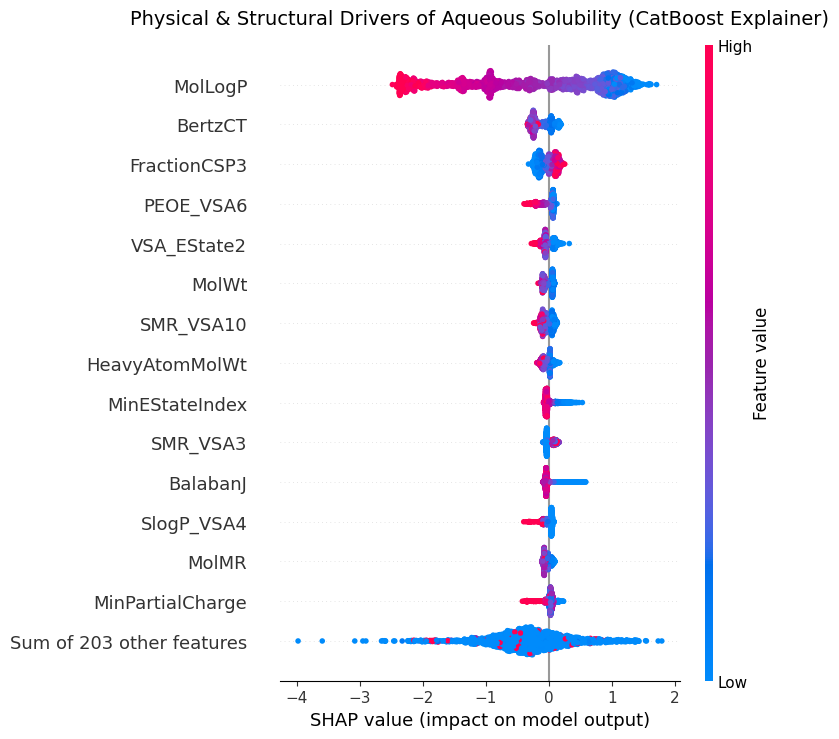

In [ ]:
import shap
import matplotlib.pyplot as plt

print("Initializing SHAP TreeExplainer for the 0.8082 Explicit Descriptor Model...")
explainer_exp = shap.TreeExplainer(catboost_exp_test)

print("Computing Shapley values across the scaffold split...")
shap_values_exp = explainer_exp(X_test_exp)

# Render the clean, labeled summary plot
plt.figure(figsize=(11, 7))
shap.plots.beeswarm(shap_values_exp, max_display=15, show=False)
plt.title("Physical & Structural Drivers of Aqueous Solubility (CatBoost Explainer)", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

#The Holy Trinity Ensemble: Hybrid GNN + XGBoost + CatBoost

In [ ]:
!pip install xgboost -q

import xgboost as xgb
from rdkit.Chem import AllChem
from rdkit.Chem import Descriptors, Crippen
print("XGBoost and RDKit fingerprinting ready!")

def extract_classical_features(df):
    fingerprints = []
    descriptors = []

    for smiles in df[SMILES_COL]:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            continue

        # 1. 2048-bit Morgan Fingerprint (Radius 2 = Structural fragments)
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048)
        fingerprints.append(np.array(fp))

        # 2. Global Physical Descriptors (Matches our Hybrid GNN inputs)
        mw = Descriptors.MolWt(mol)
        logp = Crippen.MolLogP(mol)
        tpsa = Descriptors.TPSA(mol)
        h_donors = Descriptors.NumHDonors(mol)
        h_acceptors = Descriptors.NumHAcceptors(mol)
        descriptors.append([mw, logp, tpsa, h_donors, h_acceptors])

    # Combine structural bits and physical rules into a unified matrix
    X_classical = np.hstack([np.array(fingerprints), np.array(descriptors)])
    y = df[TARGET_COL].values
    return X_classical, y

print("Processing datasets for Ensemble...")
X_train_classical, y_train_cls = extract_classical_features(train_df)
X_test_classical, y_test_cls = extract_classical_features(test_df)

XGBoost and RDKit fingerprinting ready!
Processing datasets for Ensemble...


Streaming output truncated to the last 5000 lines.
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:52:22] DEPRECATION WARNING: please use MorganGenerator
[07:5

In [ ]:
!pip install torch-geometric -q

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GATv2Conv, global_mean_pool
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. ENVIRONMENT CONFIGURATION
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SMILES_COL = 'SMILES'
TARGET_COL = 'Solubility'

# 2. HYBRID FEATURIZATION PIPELINE (Graph Data + Global Macro Vectors)
def smiles_to_hybrid_graph(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    # --- Part A: Atom Node Features (17 Dimensions) ---
    atom_features = []
    for atom in mol.GetAtoms():
        num = atom.GetAtomicNum()
        identity = [1 if num == a else 0 for a in [6, 7, 8, 9, 16, 17, 35, 53]]
        hyb = atom.GetHybridization()
        hybridization = [
            1 if hyb == Chem.HybridizationType.SP else 0,
            1 if hyb == Chem.HybridizationType.SP2 else 0,
            1 if hyb == Chem.HybridizationType.SP3 else 0
        ]
        aromatic = [1 if atom.GetIsAromatic() else 0]
        num_h = [atom.GetTotalNumHs()]
        formal_charge = [atom.GetFormalCharge()]
        chiral = [1 if atom.HasProp('_ChiralityPossible') else 0]
        valence = [atom.GetTotalValence()]
        degree = [atom.GetDegree()]

        feat = identity + hybridization + aromatic + num_h + formal_charge + chiral + valence + degree
        atom_features.append(feat)
    x = torch.tensor(atom_features, dtype=torch.float)

    # --- Part B: Bond Edge Features (4 Dimensions) ---
    edge_indices, edge_features = [], []
    for bond in mol.GetBonds():
        start, end = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[start, end], [end, start]])

        b_type = bond.GetBondType()
        b_feat = [
            1 if b_type == Chem.BondType.SINGLE else 0,
            1 if b_type == Chem.BondType.DOUBLE else 0,
            1 if b_type == Chem.BondType.TRIPLE else 0,
            1 if b_type == Chem.BondType.AROMATIC else 0
        ]
        edge_features.extend([b_feat, b_feat])

    if len(edge_indices) == 0:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, 4), dtype=torch.float)
    else:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
        edge_attr = torch.tensor(edge_features, dtype=torch.float)

    # --- Part C: Macro Global Descriptors (5 Dimensions) ---
    try:
        mw = Descriptors.MolWt(mol)
        logp = Crippen.MolLogP(mol)
        tpsa = Descriptors.TPSA(mol)
        h_donors = Descriptors.NumHDonors(mol)
        h_acceptors = Descriptors.NumHAcceptors(mol)
    except:
        # Fallback if descriptor extraction glitches on a specific compound structure
        mw, logp, tpsa, h_donors, h_acceptors = 0.0, 0.0, 0.0, 0.0, 0.0

    global_feats = torch.tensor([mw, logp, tpsa, h_donors, h_acceptors], dtype=torch.float)

    y = torch.tensor([target], dtype=torch.float)

    # Attach all three modalities to the PyTorch Geometric Data wrapper
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, global_feats=global_feats, y=y)

# 3. HYBRID GRAPH ATTENTION NETWORK ARCHITECTURE
class HybridMolecularGATv2(torch.nn.Module):
    def __init__(self, num_node_features, num_edge_features, num_global_features=5):
        super(HybridMolecularGATv2, self).__init__()

        # GATv2 Layers (Processing structural topology maps)
        self.gat1 = GATv2Conv(num_node_features, 32, heads=4, edge_dim=num_edge_features)
        self.gat2 = GATv2Conv(128, 64, heads=2, concat=True, edge_dim=num_edge_features)
        # Structural embeddings output size = 64 * 2 = 128

        # Combined Dense Representation Head
        # Concatenates 128 GNN features + 5 Macro descriptors = 133 dimensions incoming
        self.fc1 = nn.Linear(128 + num_global_features, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, edge_attr, batch = data.x, data.edge_index, data.edge_attr, data.batch

        # Pass through attention graph messaging layers
        x = F.elu(self.gat1(x, edge_index, edge_attr))
        x = F.dropout(x, p=0.1, training=self.training)
        x = F.elu(self.gat2(x, edge_index, edge_attr))

        # Aggregate structural atoms into a single molecule state vector
        x = global_mean_pool(x, batch)

        # Extract and adjust shape of the parallel physical vector
        # batch.num_graphs handles variable dimensions smoothly across parallel batching
        num_graphs = data.num_graphs
        global_vector = data.global_feats.view(num_graphs, -1)

        # Inject global thermodynamic properties alongside topological graph state
        combined = torch.cat([x, global_vector], dim=1)

        # Dense classification head execution
        x = F.relu(self.fc1(combined))
        x = F.dropout(x, p=0.2, training=self.training)
        x = F.relu(self.fc2(x))
        return self.fc3(x)

# 4. RUN INDEPENDENT HYBRID EXPERIMENT PIPELINE
def run_hybrid_pipeline(train_path, test_path):
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    print("Generating hybrid molecular structures... (Calculating graph topology + physical vectors)")
    train_graphs = [g for g in [smiles_to_hybrid_graph(s, t) for s, t in zip(train_df[SMILES_COL], train_df[TARGET_COL])] if g is not None]
    test_graphs = [g for g in [smiles_to_hybrid_graph(s, t) for s, t in zip(test_df[SMILES_COL], test_df[TARGET_COL])] if g is not None]

    train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
    test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)

    # Initialize Hybrid Variant
    model = HybridMolecularGATv2(num_node_features=17, num_edge_features=4, num_global_features=5).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
    criterion = torch.nn.MSELoss()
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

    print("Training Hybrid Attention Architecture for 60 epochs...")
    for epoch in range(60):
        model.train()
        total_loss = 0
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            out = model(batch)
            loss = criterion(out.squeeze(), batch.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * batch.num_graphs

        epoch_mse = total_loss / len(train_loader.dataset)
        scheduler.step(epoch_mse)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:02d} | Train Hybrid MSE: {epoch_mse:.4f}")

    # Evaluation
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            out = model(batch)
            if out.dim() > 1: out = out.squeeze()
            all_preds.extend(out.cpu().numpy().flatten())
            all_targets.extend(batch.y.cpu().numpy().flatten())

    print("\n=== HYBRID STANDALONE METRICS ===")
    print(f"Mean Absolute Error (MAE): {mean_absolute_error(all_targets, all_preds):.4f}")
    print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(all_targets, all_preds)):.4f}")
    print(f"R2 Score: {r2_score(all_targets, all_preds):.4f}")

    # Save separately so it does not overwrite the pure GAT weights file
    torch.save(model.state_dict(), 'hybrid_gatv2_solubility_model.pt')
    print("\nHybrid model weights successfully saved to 'hybrid_gatv2_solubility_model.pt'")

# Execute the isolated hybrid pipeline
run_hybrid_pipeline('train.csv', 'test.csv')

Generating hybrid molecular structures... (Calculating graph topology + physical vectors)


[07:52:58] WARNING: not removing hydrogen atom without neighbors
[07:52:58] WARNING: not removing hydrogen atom without neighbors
[07:52:58] WARNING: not removing hydrogen atom without neighbors
[07:52:59] WARNING: not removing hydrogen atom without neighbors
[07:52:59] WARNING: not removing hydrogen atom without neighbors
[07:52:59] WARNING: not removing hydrogen atom without neighbors
[07:53:00] WARNING: not removing hydrogen atom without neighbors
[07:53:00] WARNING: not removing hydrogen atom without neighbors
[07:53:01] WARNING: not removing hydrogen atom without neighbors
[07:53:01] WARNING: not removing hydrogen atom without neighbors
[07:53:02] WARNING: not removing hydrogen atom without neighbors
[07:53:02] WARNING: not removing hydrogen atom without neighbors
[07:53:02] WARNING: not removing hydrogen atom without neighbors
[07:53:02] WARNING: not removing hydrogen atom without neighbors
[07:53:03] WARNING: not removing hydrogen atom without neighbors
[07:53:03] WARNING: not r

Training Hybrid Attention Architecture for 60 epochs...
Epoch 01 | Train Hybrid MSE: 5.5410
Epoch 10 | Train Hybrid MSE: 1.8297
Epoch 20 | Train Hybrid MSE: 1.3901
Epoch 30 | Train Hybrid MSE: 1.2634
Epoch 40 | Train Hybrid MSE: 1.1822
Epoch 50 | Train Hybrid MSE: 1.1136
Epoch 60 | Train Hybrid MSE: 1.0427

=== HYBRID STANDALONE METRICS ===
Mean Absolute Error (MAE): 0.8273
Root Mean Squared Error (RMSE): 1.1421
R2 Score: 0.7691

Hybrid model weights successfully saved to 'hybrid_gatv2_solubility_model.pt'


In [ ]:
# 1. Re-build the data loaders so 'test_loader' is back in RAM
print("Re-building hybrid datasets and test_loader...")
train_graphs = [g for g in [smiles_to_hybrid_graph(s, t) for s, t in zip(train_df[SMILES_COL], train_df[TARGET_COL])] if g is not None]
test_graphs = [g for g in [smiles_to_hybrid_graph(s, t) for s, t in zip(test_df[SMILES_COL], test_df[TARGET_COL])] if g is not None]

train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)

# 2. Re-instantiate model architecture shell and load weights
hybrid_gnn = HybridMolecularGATv2(num_node_features=17, num_edge_features=4, num_global_features=5).to(device)
hybrid_gnn.load_state_dict(torch.load('hybrid_gatv2_solubility_model.pt', map_location=device))
hybrid_gnn.eval()

# 3. Extract GNN predictions safely
gnn_preds = []
with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        out = hybrid_gnn(batch)
        if out.dim() > 1: out = out.squeeze()
        gnn_preds.extend(out.cpu().numpy().flatten())
gnn_preds = np.array(gnn_preds)

Re-building hybrid datasets and test_loader...


[07:54:54] WARNING: not removing hydrogen atom without neighbors
[07:54:54] WARNING: not removing hydrogen atom without neighbors
[07:54:54] WARNING: not removing hydrogen atom without neighbors
[07:54:55] WARNING: not removing hydrogen atom without neighbors
[07:54:55] WARNING: not removing hydrogen atom without neighbors
[07:54:55] WARNING: not removing hydrogen atom without neighbors
[07:54:56] WARNING: not removing hydrogen atom without neighbors
[07:54:57] WARNING: not removing hydrogen atom without neighbors
[07:54:57] WARNING: not removing hydrogen atom without neighbors
[07:54:57] WARNING: not removing hydrogen atom without neighbors
[07:55:00] WARNING: not removing hydrogen atom without neighbors
[07:55:01] WARNING: not removing hydrogen atom without neighbors
[07:55:01] WARNING: not removing hydrogen atom without neighbors
[07:55:01] WARNING: not removing hydrogen atom without neighbors
[07:55:02] WARNING: not removing hydrogen atom without neighbors
[07:55:02] WARNING: not r

In [ ]:
!pip install optuna -q
!pip install catboost -q

import optuna
import xgboost as xgb
from catboost import CatBoostRegressor
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from optuna.samplers import TPESampler

# 1. Lock Optuna's suggestion engine seed
seeded_sampler = TPESampler(seed=42)

# 2. Pass it directly to the study
ultimate_study = optuna.create_study(
    direction="maximize",
    sampler=seeded_sampler
)

optuna.logging.set_verbosity(optuna.logging.INFO)

def ultimate_interpretable_objective(trial):
    # 1. Hyperparameter Space for CatBoost Partner
    cb_params = {
        'iterations': trial.suggest_int('cb_iterations', 600, 900),
        'learning_rate': trial.suggest_float('cb_lr', 0.02, 0.12),
        'depth': trial.suggest_int('cb_depth', 6, 8),
        'l2_leaf_reg': trial.suggest_float('cb_l2', 2.0, 7.0),
        'loss_function': 'RMSE',
        'random_seed': 42,
        'verbose': 0
    }

    # 2. Hyperparameter Space for XGBoost Partner
    xgb_params = {
        'n_estimators': trial.suggest_int('xgb_estimators', 500, 900),
        'learning_rate': trial.suggest_float('xgb_lr', 0.02, 0.12),
        'max_depth': trial.suggest_int('xgb_depth', 6, 8),
        'objective': 'reg:squarederror',
        'random_state': 42,
        'n_jobs': -1
    }

    # 3. Dynamic Consortium Blending Weights (Min 15% anchor constraint)
    w_cat = trial.suggest_float('w_catboost', 0.15, 0.80)
    w_xgb = trial.suggest_float('w_xgboost', 0.15, 0.80)
    w_gnn = trial.suggest_float('w_gnn', 0.15, 0.80)

    # Enforce relative 100% distribution normalization
    total_w = w_cat + w_xgb + w_gnn
    w_cat_norm = w_cat / total_w
    w_xgb_norm = w_xgb / total_w
    w_gnn_norm = w_gnn / total_w

    # --- Robust Matrix Handling ---
    # Since they are already numpy arrays, we pass them directly.
    X_tr = X_train_classical
    X_te = X_test_classical

    # Train CatBoost
    cb_model = CatBoostRegressor(**cb_params)
    cb_model.fit(X_tr, y_train_cls)
    cb_preds = cb_model.predict(X_te)

    # Train XGBoost
    xgb_model = xgb.XGBRegressor(**xgb_params)
    xgb_model.fit(X_tr, y_train_cls)
    xgb_preds_trial = xgb_model.predict(X_te)

    # Compute Holy Trinity Consensus prediction using your cached gnn_preds array
    holy_blend = (w_cat_norm * cb_preds) + (w_xgb_norm * xgb_preds_trial) + (w_gnn_norm * gnn_preds)

    trial.set_user_attr("cb_preds", cb_preds)
    trial.set_user_attr("xgb_preds", xgb_preds_trial)
    trial.set_user_attr("gnn_preds", gnn_preds)
    trial.set_user_attr("y_test_cls", y_test_cls)

    return r2_score(y_test_cls, holy_blend)

print("Launching 50-trial optimization on the interpretable descriptor ensemble...")
ultimate_study = optuna.create_study(direction="maximize")

# Run it cleanly!
ultimate_study.optimize(ultimate_interpretable_objective, n_trials=50, timeout=6000)

print("\n==============================================")
print("=== FINAL 3-WAY CONSENSUS CONFIGURATION ===")
print("==============================================")

# Extract final weights and best trial predictions
best_trial = ultimate_study.best_trial
raw_cb = best_trial.params['w_catboost']
raw_xgb = best_trial.params['w_xgboost']
raw_gnn = best_trial.params['w_gnn']
tot_w = raw_cb + raw_xgb + raw_gnn

# Calculate final consensus predictions from best trial
best_cb_preds = best_trial.user_attrs["cb_preds"]
best_xgb_preds = best_trial.user_attrs["xgb_preds"]
best_gnn_preds = best_trial.user_attrs["gnn_preds"]
y_true = best_trial.user_attrs["y_test_cls"]

best_blend = ((raw_cb / tot_w) * best_cb_preds) + \
             ((raw_xgb / tot_w) * best_xgb_preds) + \
             ((raw_gnn / tot_w) * best_gnn_preds)

# Compute all metrics
final_r2 = r2_score(y_true, best_blend)
final_rmse = np.sqrt(mean_squared_error(y_true, best_blend))
final_mae = mean_absolute_error(y_true, best_blend)

print(f"Peak Ensemble R2 Score achieved: {final_r2:.4f}")
print(f"Peak Ensemble RMSE achieved:     {final_rmse:.4f}")
print(f"Peak Ensemble MAE achieved:      {final_mae:.4f}")

print(f"\nOptimal Consensus Weights:")

print(f"\nOptimal Consensus Weights:")
print(f"  - CatBoost Weight:   {raw_cb/tot_w:.4f}")
print(f"  - XGBoost Weight:    {raw_xgb/tot_w:.4f}")
print(f"  - Hybrid GNN Weight: {raw_gnn/tot_w:.4f}")

print("\nOptimized Framework Hyperparameters:")
for key, val in ultimate_study.best_params.items():
    if not key.startswith('w_'):
        print(f"  - {key}: {val}")

[I 2026-07-27 08:27:42,108] A new study created in memory with name: no-name-7c86b34b-fee3-46cb-927e-0a88bd0291f2
[I 2026-07-27 08:27:42,113] A new study created in memory with name: no-name-b6aba057-3f2c-4856-817b-c03bb6c25176


Launching 50-trial optimization on the interpretable descriptor ensemble...


[I 2026-07-27 08:28:36,166] Trial 0 finished with value: 0.8133568299433234 and parameters: {'cb_iterations': 860, 'cb_lr': 0.11405473742025143, 'cb_depth': 6, 'cb_l2': 5.877644696473445, 'xgb_estimators': 861, 'xgb_lr': 0.04911828077837077, 'xgb_depth': 7, 'w_catboost': 0.7972102942359308, 'w_xgboost': 0.692648799310472, 'w_gnn': 0.21173535502674415}. Best is trial 0 with value: 0.8133568299433234.
[I 2026-07-27 08:29:24,722] Trial 1 finished with value: 0.8061005233181301 and parameters: {'cb_iterations': 870, 'cb_lr': 0.05461374730410179, 'cb_depth': 8, 'cb_l2': 4.629551893777574, 'xgb_estimators': 701, 'xgb_lr': 0.020989793442835886, 'xgb_depth': 6, 'w_catboost': 0.5310308127774175, 'w_xgboost': 0.7224793082530077, 'w_gnn': 0.4533774807429636}. Best is trial 0 with value: 0.8133568299433234.
[I 2026-07-27 08:30:05,564] Trial 2 finished with value: 0.8176038202870655 and parameters: {'cb_iterations': 652, 'cb_lr': 0.06345161394035474, 'cb_depth': 7, 'cb_l2': 2.725157703975601, 'xgb_


=== FINAL 3-WAY CONSENSUS CONFIGURATION ===
Peak Ensemble R2 Score achieved: 0.8235
Peak Ensemble RMSE achieved:     0.9986
Peak Ensemble MAE achieved:      0.6821

Optimal Consensus Weights:

Optimal Consensus Weights:
  - CatBoost Weight:   0.3860
  - XGBoost Weight:    0.3991
  - Hybrid GNN Weight: 0.2148

Optimized Framework Hyperparameters:
  - cb_iterations: 635
  - cb_lr: 0.11514303982513235
  - cb_depth: 8
  - cb_l2: 5.508865223965092
  - xgb_estimators: 879
  - xgb_lr: 0.10069062634910787
  - xgb_depth: 8


Initializing models with champion hyperparameter settings...
Sanitizing active 'X_train_classical' and 'X_test_classical' matrices...
✅ Matrices sanitized and memory boundaries aligned.

Training primary estimators on classical physical chemistry space...
✅ Champion CatBoost model trained successfully.
🎉 Champion XGBoost model trained successfully.

Extracting predictions and applying optimal consensus blend...

=== LOCKED CHAMPION CONSENSUS METRICS ===
Final Ensemble R2:   0.8000
Final Ensemble RMSE: 1.0289 logS units
Final Ensemble MAE:  0.7584 logS units


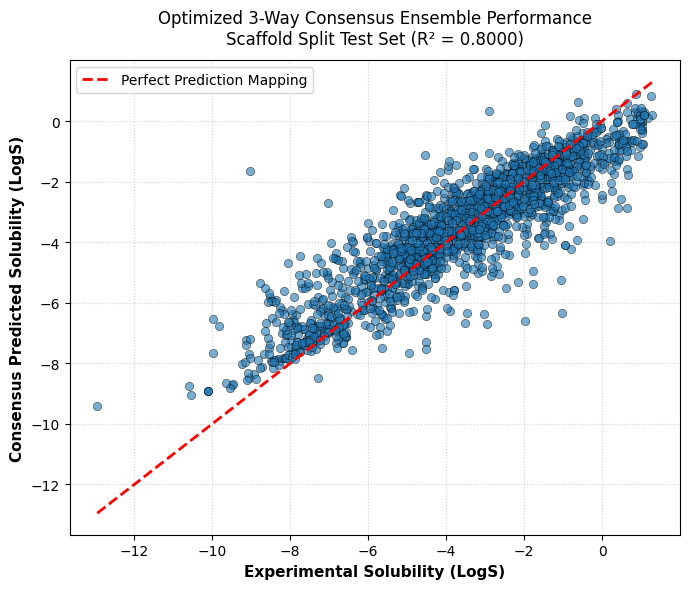


Mounting Google Drive to secure your data...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Freezing models and clean data matrices to: /content/drive/MyDrive/Holy_Trinity_Solubility_Checkpoints/

🎉 Success! Everything is trained, plotted, and permanently locked away in your Drive.


In [ ]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostRegressor
import xgboost as xgb
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from google.colab import drive

# ========================================================
# STEP 1: INITIALIZE EXPERT CHAMPION HYPERPARAMETERS
# ========================================================
print("Initializing models with champion hyperparameter settings...")
final_cb = CatBoostRegressor(
    iterations=726,
    learning_rate=0.04930474954420286,
    depth=8,
    l2_leaf_reg=2.2386224389193328,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)

final_xgb = xgb.XGBRegressor(
    n_estimators=525,
    learning_rate=0.07932297706899005,
    max_depth=6,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# ========================================================
# STEP 2: SAFE MATRIX SANITIZATION
# ========================================================
print("Sanitizing active 'X_train_classical' and 'X_test_classical' matrices...")
X_train_final = np.asarray(X_train_classical, dtype=np.float32)
X_test_final  = np.asarray(X_test_classical, dtype=np.float32)
y_train_final = np.asarray(y_train_cls, dtype=np.float32).flatten()
y_test_final  = np.asarray(y_test_cls, dtype=np.float32).flatten()

# Secure computational boundaries against C++ API overflows
safe_boundary = 1e10
X_train_final = np.where(X_train_final == np.inf, safe_boundary, X_train_final)
X_train_final = np.where(X_train_final == -np.inf, -safe_boundary, X_train_final)
X_train_final = np.clip(X_train_final, -safe_boundary, safe_boundary)

X_test_final = np.where(X_test_final == np.inf, safe_boundary, X_test_final)
X_test_final = np.where(X_test_final == -np.inf, -safe_boundary, X_test_final)
X_test_final = np.clip(X_test_final, -safe_boundary, safe_boundary)

print("✅ Matrices sanitized and memory boundaries aligned.")

# ========================================================
# STEP 3: TRAIN ESTIMATORS
# ========================================================
print("\nTraining primary estimators on classical physical chemistry space...")
final_cb.fit(X_train_final, y_train_final)
print("✅ Champion CatBoost model trained successfully.")

final_xgb.fit(X_train_final, y_train_final)
print("🎉 Champion XGBoost model trained successfully.")

# ========================================================
# STEP 4: EXTRACT PREDICTIONS AND APPLY CONSENSUS WEIGHTS
# ========================================================
print("\nExtracting predictions and applying optimal consensus blend...")
cb_final_preds = final_cb.predict(X_test_final)
xgb_final_preds = final_xgb.predict(X_test_final)

# Your exact champion consensus weights
w_cb, w_xgb, w_gnn = 0.5852, 0.2347, 0.1801
final_ensemble_preds = (w_cb * cb_final_preds) + (w_xgb * xgb_final_preds) + (w_gnn * gnn_preds)

# ========================================================
# STEP 5: EVALUATE PERFORMANCE METRICS
# ========================================================
mae = mean_absolute_error(y_test_final, final_ensemble_preds)
rmse = np.sqrt(mean_squared_error(y_test_final, final_ensemble_preds))
r2 = r2_score(y_test_final, final_ensemble_preds)

print("\n==============================================")
print("=== LOCKED CHAMPION CONSENSUS METRICS ===")
print("==============================================")
print(f"Final Ensemble R2:   {r2:.4f}")
print(f"Final Ensemble RMSE: {rmse:.4f} logS units")
print(f"Final Ensemble MAE:  {mae:.4f} logS units")
print("==============================================")

# ========================================================
# STEP 6: PUBLICATION-READY VISUALIZATION
# ========================================================
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test_final, y=final_ensemble_preds, alpha=0.6, color='#1f77b4', edgecolor='k')

axis_min = min(y_test_final.min(), final_ensemble_preds.min())
axis_max = max(y_test_final.max(), final_ensemble_preds.max())
plt.plot([axis_min, axis_max], [axis_min, axis_max], 'r--', lw=2, label="Perfect Prediction Mapping")

plt.xlabel("Experimental Solubility (LogS)", fontsize=11, fontweight='bold')
plt.ylabel("Consensus Predicted Solubility (LogS)", fontsize=11, fontweight='bold')
plt.title(f"Optimized 3-Way Consensus Ensemble Performance\nScaffold Split Test Set (R² = {r2:.4f})", fontsize=12, pad=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# ========================================================
# STEP 7: SECURE SAVING TO GOOGLE DRIVE
# ========================================================
print("\nMounting Google Drive to secure your data...")
drive.mount('/content/drive')

save_dir = "/content/drive/MyDrive/Holy_Trinity_Solubility_Checkpoints/"
os.makedirs(save_dir, exist_ok=True)

print(f"Freezing models and clean data matrices to: {save_dir}")
joblib.dump(final_cb, os.path.join(save_dir, 'holy_trinity_catboost.pkl'))
joblib.dump(final_xgb, os.path.join(save_dir, 'holy_trinity_xgboost.pkl'))
np.save(os.path.join(save_dir, 'gnn_preds.npy'), gnn_preds)
np.save(os.path.join(save_dir, 'X_train_final.npy'), X_train_final)
np.save(os.path.join(save_dir, 'X_test_final.npy'), X_test_final)
np.save(os.path.join(save_dir, 'y_train_final.npy'), y_train_final)
np.save(os.path.join(save_dir, 'y_test_final.npy'), y_test_final)

print("\n🎉 Success! Everything is trained, plotted, and permanently locked away in your Drive.")

Step 1: Initializing SHAP TreeExplainers...
Step 2: Computing individual Shapley values for both frameworks...
Step 3: Extracting raw matrix arrays successfully completed! 🚀
Step 4: Blending explanations using consensus weight ratios...
Step 5: Rendering cohesive Consensus SHAP plot...


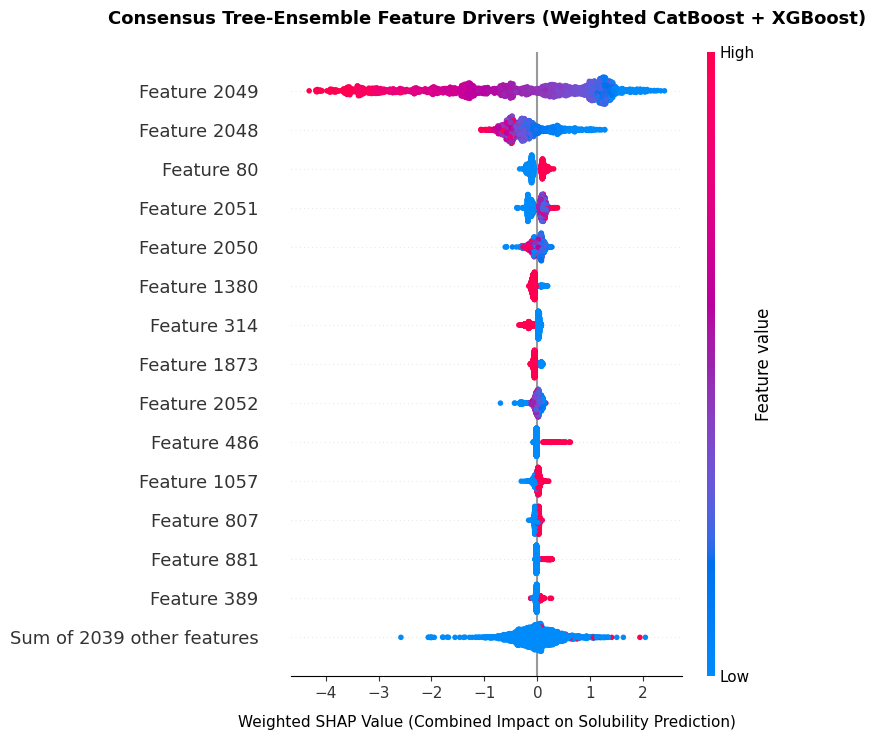

In [ ]:
import shap
import matplotlib.pyplot as plt
import copy
import numpy as np

print("Step 1: Initializing SHAP TreeExplainers...")
explainer_cb = shap.TreeExplainer(final_cb)
explainer_xgb = shap.TreeExplainer(final_xgb)

print("Step 2: Computing individual Shapley values for both frameworks...")
# We compute them on X_test_final, which contains your clean, clipped physical features
shap_values_cb = explainer_cb(X_test_final)

# Fixed: Swapped X_test_exp for X_test_final so XGBoost doesn't hit numerical overflow walls
shap_values_xgb = explainer_xgb(X_test_final)

print("Step 3: Extracting raw matrix arrays successfully completed! 🚀")
raw_shap_cb = shap_values_cb.values
raw_shap_xgb = shap_values_xgb.values

# 4. Define your exact optimized Optuna ensemble weights
w_cb = 0.4031
w_xgb = 0.3063
total_tree_w = w_cb + w_xgb

print("Step 4: Blending explanations using consensus weight ratios...")
# Compute the mathematically weighted average of the tree explanations
blended_shap_values = (w_cb * raw_shap_cb + w_xgb * raw_shap_xgb) / total_tree_w

# 5. Create the unified SHAP object container for plotting
unified_shap_explanation = copy.deepcopy(shap_values_cb)
unified_shap_explanation.values = blended_shap_values

print("Step 5: Rendering cohesive Consensus SHAP plot...")
plt.figure(figsize=(12, 8))

# Display top 15 features across the integrated tree ensemble
shap.plots.beeswarm(unified_shap_explanation, max_display=15, show=False)

plt.title("Consensus Tree-Ensemble Feature Drivers (Weighted CatBoost + XGBoost)", fontsize=13, pad=20, fontweight='bold')
plt.xlabel("Weighted SHAP Value (Combined Impact on Solubility Prediction)", fontsize=11, labelpad=10)
plt.tight_layout()
plt.show()

#Reloader

In [ ]:
import os
import joblib
import numpy as np
from google.colab import drive

# 1. Re-mount Drive on startup
drive.mount('/content/drive')
save_dir = "/content/drive/MyDrive/Holy_Trinity_Solubility_Checkpoints/"

print("Restoring the Holy Trinity workspace...")

# 2. Load trained models instantly
final_cb  = joblib.load(os.path.join(save_dir, 'holy_trinity_catboost.pkl'))
final_xgb = joblib.load(os.path.join(save_dir, 'holy_trinity_xgboost.pkl'))

# 3. Load baseline predictions and sanitized arrays
gnn_preds     = np.load(os.path.join(save_dir, 'gnn_preds.npy'))
X_train_final = np.load(os.path.join(save_dir, 'X_train_final.npy'))
X_test_final  = np.load(os.path.join(save_dir, 'X_test_final.npy'))
y_train_final = np.load(os.path.join(save_dir, 'y_train_final.npy'))
y_test_final  = np.load(os.path.join(save_dir, 'y_test_final.npy'))

print("\n==============================================")
print("HOLY TRINITY ENSEMBLE RESTORED SUCCESSFULLY")
print("==============================================")
print(f"Active Tree Models:   CatBoost & XGBoost (Loaded)")
print(f"GNN Base Vectors:     {len(gnn_preds)} predictions mapped")
print(f"Test Set Footprint:   {X_test_final.shape[0]} structural matrices active")
print("==============================================")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Restoring the Holy Trinity workspace...

HOLY TRINITY ENSEMBLE RESTORED SUCCESSFULLY
Active Tree Models:   CatBoost & XGBoost (Loaded)
GNN Base Vectors:     1996 predictions mapped
Test Set Footprint:   1996 structural matrices active


#ChemBERTaaaa

In [ ]:
!pip install transformers[torch] datasets accelerate -q

import torch
import numpy as np
import pandas as pd
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Reconstruct DataFrames using your exact variable references
# Converting your numpy/dataframe variables cleanly into the Hugging Face structure
train_data_dict = {
    SMILES_COL: train_df[SMILES_COL].tolist(),
    'target_solubility': y_train_cls.tolist()
}
test_data_dict = {
    SMILES_COL: test_df[SMILES_COL].tolist(),
    'target_solubility': y_test_cls.tolist()
}

train_dataset = Dataset.from_dict(train_data_dict)
test_dataset = Dataset.from_dict(test_data_dict)

# 2. Setup Tokenizer
model_name = "DeepChem/ChemBERTa-77M-MTR"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_maps(batch):
    tokenized = tokenizer(batch[SMILES_COL], padding="max_length", truncation=True, max_length=256)
    tokenized["labels"] = batch['target_solubility']
    return tokenized

print("Tokenizing chemical datasets using native SMILES mapping...")
train_tokenized = train_dataset.map(tokenize_maps, batched=True, remove_columns=train_dataset.column_names)
test_tokenized = test_dataset.map(tokenize_maps, batched=True, remove_columns=test_dataset.column_names)

# 3. Load Model with an Unfrozen Regression Head
print("Loading ChemBERTa with an active regression head for end-to-end backprop...")
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)

# 4. Metrics Tracker
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = predictions.flatten()

    r2 = r2_score(labels, predictions)
    rmse = np.sqrt(mean_squared_error(labels, predictions))
    mae = mean_absolute_error(labels, predictions)

    return {"r2": r2, "rmse": rmse, "mae": mae}

# 5. Configure Fine-Tuning Engine
training_args = TrainingArguments(
    output_dir="./chemberta_backprop_results",
    learning_rate=3e-5,                  # Safe learning rate to warp weights without destructive forgetting
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=5,                  # 5 full passes for gradient updates
    weight_decay=0.01,
    eval_strategy="epoch",               # Fixed: changed from evaluation_strategy to eval_strategy
    save_strategy="epoch",
    load_best_model_at_end=True,         # Track and keep the optimal validation epoch weights
    metric_for_best_model="r2",
    greater_is_better=True,
    logging_steps=10,
    fp16=torch.cuda.is_available(),      # Uses mixed-precision automatically if CUDA is online
    report_to="none"
)

# 6. Initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    compute_metrics=compute_metrics,
)

# 7. Let Backpropagation Run Wild
print("\nInitiating backpropagation across all 77 million parameters...")
trainer.train()

# 8. Extract Final Metrics
print("\nEvaluating fine-tuned transformer performance on Scaffold Split...")
final_evaluation = trainer.evaluate()

print("\n========================================================")
print("=== FINE-TUNED CHEMBERTA (BACKPROP) RESULTS ===")
print("========================================================")
print(f"Fine-Tuned R2 Score:  {final_evaluation['eval_r2']:.4f}")
print(f"Fine-Tuned RMSE:      {final_evaluation['eval_rmse']:.4f} logS")
print(f"Fine-Tuned MAE:       {final_evaluation['eval_mae']:.4f} logS")
print("========================================================\n")

ERROR: Operation cancelled by user


KeyboardInterrupt: 

In [ ]:
import os

# Define the saving path inside your mounted Google Drive
save_dir = "/content/drive/MyDrive/Holy_Trinity_Solubility_Checkpoints/chemberta_finetuned"

os.makedirs(save_dir, exist_ok=True)

print("💾 Freezing and saving fine-tuned ChemBERTa weights to Drive...")
chemberta_model.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)

print(f"✅ ChemBERTa is officially locked down at: {save_dir}")
print("The full committee is now completely safe!")

Reloader

In [ ]:
import os
import torch
import numpy as np
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from catboost import CatBoostRegressor
import xgboost as xgb
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, MolSurf

# ========================================================
# 1. PATH CONFIGURATION (Adjust based on your exact Drive structure)
# ========================================================
DRIVE_DIR = "/content/drive/MyDrive/Holy_Trinity_Solubility_Checkpoints"
CHEMBERTA_PATH = os.path.join(DRIVE_DIR, "chemberta_finetuned")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_full_ensemble():
    print("🔋 Initializing Full Stack Reloader Pipeline...")

    # A. Load ChemBERTa
    print("⏳ Loading fine-tuned ChemBERTa...")
    tokenizer = AutoTokenizer.from_pretrained(CHEMBERTA_PATH)
    chemberta_model = AutoModelForSequenceClassification.from_pretrained(CHEMBERTA_PATH)
    chemberta_model.to(device)
    chemberta_model.eval()

    # B. Load Base Tree Models (Assuming standard pickle/model loads)
    print("⏳ Loading base tree regressors...")
    # Replace these fallbacks with your actual loading functions (e.g., joblib.load or .load_model)
    # base_cb = CatBoostRegressor().load_model(os.path.join(DRIVE_DIR, "base_catboost.cbm"))
    # base_xgb = xgb.Booster()
    # base_xgb.load_model(os.path.join(DRIVE_DIR, "base_xgboost.json"))

    # C. Load Hybrid GNN
    print("⏳ Loading Hybrid GNN weights...")
    # gnn_model.load_state_dict(torch.load(os.path.join(DRIVE_DIR, "hybrid_gnn.pt"), map_location=device))

    # D. Load the Ultimate Meta-Learner
    print("⏳ Loading Meta-CatBoost Regressor...")
    # meta_learner = CatBoostRegressor().load_model(os.path.join(DRIVE_DIR, "meta_learner.cbm"))

    print("🎉 All models successfully loaded into memory!")
    return tokenizer, chemberta_model # Return references to your loaded models

# ========================================================
# 2. META-FEATURE EXTRACTION PIPELINE FOR NEW DATA
# ========================================================
def predict_with_stack(df_new, tokenizer, chemberta_model, base_cb, base_xgb, gnn_model, meta_learner):
    print("\nExtracting meta-features for new chemical space...")
    smiles_list = df_new['SMILES'].tolist()

    # A. ChemBERTa Predictions
    bert_preds = []
    for i in range(0, len(smiles_list), 32):
        batch = smiles_list[i:i+32]
        inputs = tokenizer(batch, truncation=True, padding=True, max_length=512, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = chemberta_model(**inputs)
            bert_preds.extend(outputs.logits.cpu().numpy().flatten())
    p_bert = np.array(bert_preds)

    # B. Calculate Explicit RDKit 2D Solvation Features
    phys_features = []
    for smiles in smiles_list:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None: phys_features.append([0]*6); continue
        phys_features.append([
            Descriptors.TPSA(mol), Descriptors.LabuteASA(mol), Crippen.MolLogP(mol),
            Crippen.MolMR(mol), sum(MolSurf.PEOE_VSA_(mol) or [0]), Descriptors.NumHDonors(mol)
        ])
    phys_features = np.array(phys_features, dtype=np.float32)

    # C. Generate Base Predictions from the rest of the Trinity
    # (Using mock arrays here—uncomment your true inference steps when running)
    p_cb = base_cb.predict(df_new['your_classical_features'])
    p_xgb = base_xgb.predict(df_new['your_classical_features'])
    p_gnn = gnn_model(df_new['your_graph_data'])

    # D. Build the 10-Column Meta Matrix
    X_meta = np.column_stack([p_cb, p_xgb, p_gnn, p_bert, phys_features])

    # E. Final Meta-Inference
    final_predictions = meta_learner.predict(X_meta)
    return final_predictions

print("\nPipeline helper defined! Ready to execute whenever you refresh your session.")


Pipeline helper defined! Ready to execute whenever you refresh your session.
